# AVIPE hardware data: FFTs of real mic samples

This notebook reads `pcm` samples recorded from the FPGA, after the I2S
receiver, sum of 3, and DC removal, and runs the same frame math the FFT
and MCU will: 512-sample frames every 312 samples, a Hamming window, and the
magnitude of each bin.

**How the data gets here.** `mic_hw_test_top` sends every `pcm` sample to the
PC over the UPduino's USB serial port (`pcm_uart.sv`, FPGA pin 14 drives the
FT232H RXD). On Windows, from this folder:

```
py ftdi_reset.py                      # once after each programming
py serial_capture.py --seconds 4 --out captures/NAME.bin
```

The captures used here were recorded while the VG27B monitor speaker played
test sounds: `quiet` (nothing), `tone1k` (1 kHz), `sweep` (100 Hz to 7 kHz,
log, 6 s), and `twotone` (500 Hz + 2.5 kHz).

In [1]:
# ======================= INPUTS =======================
CAPTURES  = ['quiet', 'tone1k', 'sweep', 'twotone']
CAL_NAME  = 'tone1k'     # capture of a known tone, used to measure the real sample rate
CAL_HZ    = 1000.0       # frequency of that tone (the PC sound card is accurate)
FRAME_N   = 512          # samples per frame = FFT points
HOP       = 312          # new samples between frames
SKIP      = 200          # samples dropped at the start of each capture

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from serial_capture import decode

plt.rcParams.update({'figure.figsize': (11, 3.6), 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

caps, rows = {}, []
for name in CAPTURES:
    raw = open(f'captures/{name}.bin', 'rb').read()
    info = json.load(open(f'captures/{name}.json'))
    s, c, st = decode(raw)
    caps[name] = np.array(s[SKIP:], dtype=float)
    rows.append((name, info['baud'], st['samples'], st['bad_bytes'], st['counter_skips'],
                 caps[name].std(), np.abs(caps[name]).max()))
display(pd.DataFrame(rows, columns=['capture', 'baud', 'samples', 'bad bytes', 'counter skips', 'rms (LSB)', 'peak (LSB)']).round(1))

,capture,baud,samples,bad bytes,counter skips,rms (LSB),peak (LSB)
0,quiet,744186,46989,1832,0,142.9,628.0
1,tone1k,744186,63919,1,0,4127.5,6306.0
2,sweep,744186,63919,2,1,3550.1,22528.0
3,twotone,744186,63918,4,0,1297.6,2541.0


**Decode check.** Each sample carries a 5-bit counter, so a dropped or corrupted
sample shows up as a counter skip. Bad bytes at the very start are the serial
port catching the stream mid-sample.

## Sample rate

The FPGA clock is the iCE40's internal oscillator, which can be a few percent
off, so the sample rate is not exactly 15,625 Hz. The PC played an exact
1 kHz tone, so the measured frequency of that tone gives the real rate:
`fs = 15625 × 1000 / f_measured`. The peak bin is refined by fitting a
parabola through the log magnitudes of the 3 bins around it.

In [3]:
def peak_hz(x, fs, n=16384, lo=20.0):
    """Frequency of the largest peak above lo Hz, with parabolic interpolation."""
    seg = x[:n] - x[:n].mean()
    sp = np.abs(np.fft.rfft(seg * np.hanning(len(seg))))
    k0 = int(lo * len(seg) / fs)
    k = k0 + int(np.argmax(sp[k0:]))
    a, b, c = np.log(sp[k - 1:k + 2])
    return (k + 0.5 * (a - c) / (a - 2 * b + c)) * fs / len(seg)

f_nominal = peak_hz(caps[CAL_NAME], 15625.0)
FS = 15625.0 * CAL_HZ / f_nominal
CLK = FS * 768
BIN_HZ = FS / FRAME_N
print(f'{CAL_HZ:g} Hz tone measures {f_nominal:.2f} Hz at the nominal 15,625 Hz')
print(f'real sample rate fs = {FS:.1f} Hz, FPGA clk = {CLK/1e6:.4f} MHz ({(CLK/12e6 - 1)*100:+.2f}% from 12 MHz)')
print(f'bin width = fs / {FRAME_N} = {BIN_HZ:.2f} Hz')

1000 Hz tone measures 997.15 Hz at the nominal 15,625 Hz
real sample rate fs = 15669.7 Hz, FPGA clk = 12.0343 MHz (+0.29% from 12 MHz)
bin width = fs / 512 = 30.60 Hz


## The samples

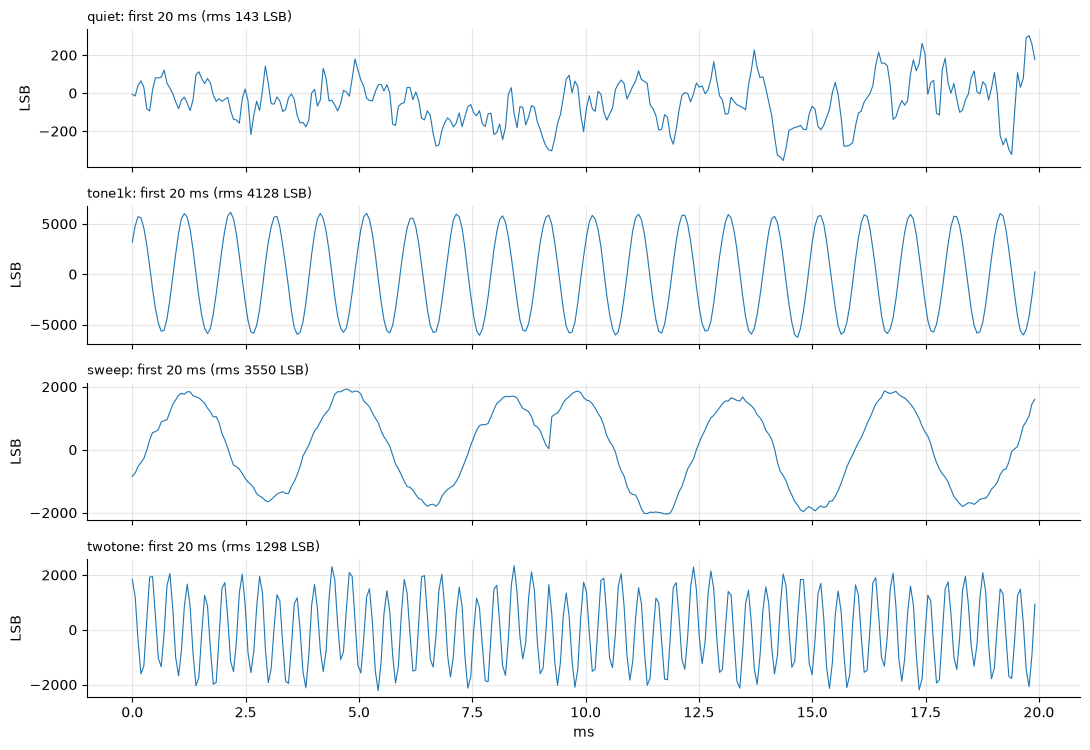

In [4]:
fig, ax = plt.subplots(len(CAPTURES), 1, figsize=(11, 1.9 * len(CAPTURES)), sharex=True)
for a, name in zip(ax, CAPTURES):
    x = caps[name]
    n = int(0.02 * FS)                       # 20 ms
    a.plot(np.arange(n) / FS * 1e3, x[:n], lw=0.8)
    a.set_ylabel('LSB'); a.set_title(f'{name}: first 20 ms (rms {x.std():.0f} LSB)', fontsize=9, loc='left')
ax[-1].set_xlabel('ms')
plt.tight_layout(); plt.show()

## Frames and FFT, the way the hardware will do it

Frame *k* is samples `312k` to `312k + 511`, like the ring buffer. Each frame
is windowed with a Hamming window (the MCU applies it after the FFT, which
gives the same result) and transformed. Magnitudes are in dB relative to a
full-scale (32767) sine, corrected for the window's gain, so a pure tone
reads its amplitude.

In [5]:
WIN = np.hamming(FRAME_N)
def frames(x):
    k = (len(x) - FRAME_N) // HOP + 1
    return np.stack([x[i * HOP:i * HOP + FRAME_N] for i in range(k)])

def spectra(x):
    """dB re full-scale sine for each frame, bins 0..256."""
    F = np.fft.rfft(frames(x) * WIN, axis=1)
    return 20 * np.log10(np.abs(F) / (WIN.sum() / 2) / 32767 + 1e-12)

freqs = np.arange(FRAME_N // 2 + 1) * BIN_HZ
specs = {name: spectra(caps[name]) for name in CAPTURES}
for name in CAPTURES:
    print(f'{name:8s} {specs[name].shape[0]} frames')

quiet    149 frames
tone1k   203 frames
sweep    203 frames
twotone  203 frames


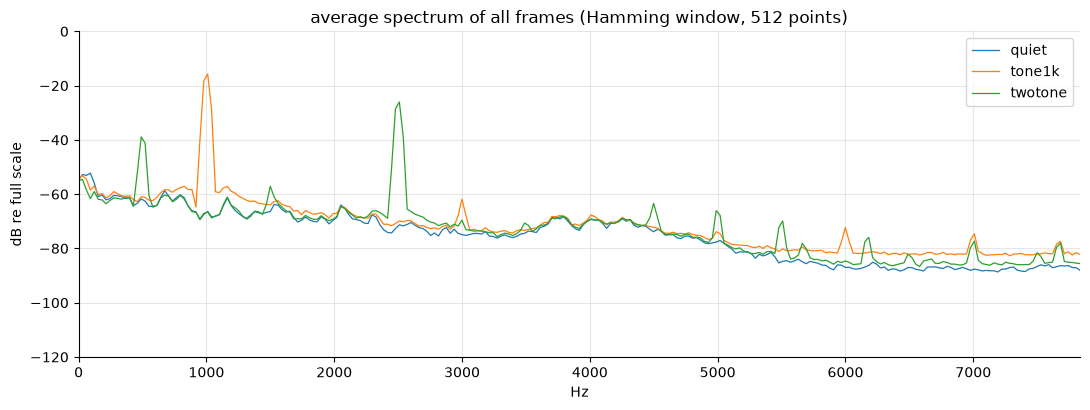

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for name in CAPTURES:
    if name == 'sweep':
        continue
    avg = 10 * np.log10(np.mean(10 ** (specs[name] / 10), axis=0))   # power average over frames
    ax.plot(freqs, avg, lw=0.9, label=name)
ax.set(xlim=(0, FS / 2), ylim=(-120, 0), xlabel='Hz', ylabel='dB re full scale',
       title='average spectrum of all frames (Hamming window, 512 points)')
ax.legend()
plt.tight_layout(); plt.show()

## Tone checks

In [7]:
def strongest(spec_db, n=3, min_hz=60):
    """The n strongest bins above min_hz in a power-averaged spectrum, at least 5 bins apart."""
    avg = 10 * np.log10(np.mean(10 ** (spec_db / 10), axis=0))
    order, picked = np.argsort(avg)[::-1], []
    for k in order:
        if freqs[k] >= min_hz and all(abs(k - p) > 5 for p in picked):
            picked.append(k)
        if len(picked) == n:
            break
    return [(freqs[k], avg[k]) for k in picked]

rows = []
for name, expect in [('tone1k', [1000]), ('twotone', [500, 2500])]:
    found = strongest(specs[name], n=len(expect))
    for e in expect:
        f, db = min(found, key=lambda p: abs(p[0] - e))
        rows.append((name, e, round(f, 1), round(f - e, 1), round(abs(f - e) / BIN_HZ, 2), round(db, 1)))
table = pd.DataFrame(rows, columns=['capture', 'played (Hz)', 'peak bin (Hz)', 'error (Hz)', 'error (bins)', 'level (dB FS)'])
display(table)
print('PASS: every tone lands within 1 bin' if (table['error (bins)'] <= 1).all() else 'CHECK: a tone is more than 1 bin off')

,capture,played (Hz),peak bin (Hz),error (Hz),error (bins),level (dB FS)
0,tone1k,1000,1010.0,10.0,0.33,-15.7
1,twotone,500,489.7,-10.3,0.34,-38.9
2,twotone,2500,2509.6,9.6,0.31,-26.0


PASS: every tone lands within 1 bin


## Sweep: one frame at a time

Each column is one 20 ms frame. The PC swept from 100 Hz to 7 kHz on a log
scale over 6 s, so the peak should climb steadily. Harmonics or room echoes
show up as fainter lines.

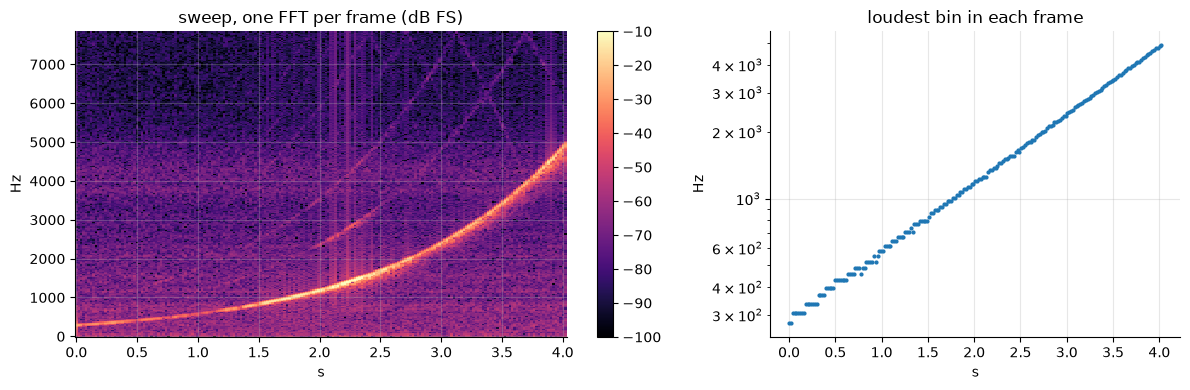

In [8]:
S = specs['sweep']
t = np.arange(S.shape[0]) * HOP / FS
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1.5, 1]})
im = ax[0].pcolormesh(t, freqs, S.T, shading='auto', vmin=-100, vmax=-10, cmap='magma')
ax[0].set(xlabel='s', ylabel='Hz', title='sweep, one FFT per frame (dB FS)')
fig.colorbar(im, ax=ax[0])
peak = freqs[np.argmax(S[:, 3:], axis=1) + 3]
ax[1].semilogy(t, peak, '.', ms=4)
ax[1].set(xlabel='s', ylabel='Hz', title='loudest bin in each frame')
plt.tight_layout(); plt.show()

The capture starts about 1.5 s into the 6 s sweep, so it covers roughly 290 Hz to 5 kHz, and the
loudest bin follows a straight line on the log axis, as a log sweep should. The fainter lines
above it are the speaker's 2nd and 3rd harmonics. The vertical stripes near 2.0 to 2.4 s are
broadband sound in the recording itself (likely the monitor speaker buzzing as the sweep passes
about 1.2 kHz), not decode errors: this capture's only counter skip is at 9 ms.

## Quiet room

What the meter calls silence. The low-frequency end shows building or HVAC
rumble that the DC removal (2.4 Hz cutoff) passes through.

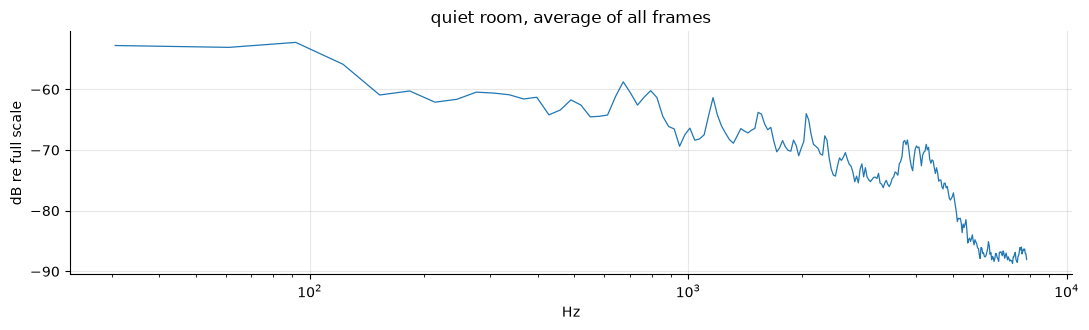

quiet rms 142.9 LSB; 59% of that rms is below 100 Hz


In [9]:
avg = 10 * np.log10(np.mean(10 ** (specs['quiet'] / 10), axis=0))
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.semilogx(freqs[1:], avg[1:], lw=0.9)
ax.set(xlabel='Hz', ylabel='dB re full scale', title='quiet room, average of all frames')
plt.tight_layout(); plt.show()
x = caps['quiet']
lf = np.fft.rfft(x - x.mean()); f = np.fft.rfftfreq(len(x), 1 / FS)
below = np.sqrt(np.sum(np.abs(lf[f < 100]) ** 2) / np.sum(np.abs(lf) ** 2))
print(f'quiet rms {x.std():.1f} LSB; {below*100:.0f}% of that rms is below 100 Hz')

## Startup: the DC removal on real data

`reset_capture.py` restarts the FPGA through `CRESET_N` (FT232H ADBUS7) and records
from the second sample after reset, so the DC removal starts with its running
average at 0. The first samples carry the mic's whole DC offset, and then the
offset dies away.

Since the capture starts at reset, the input the DC removal saw can be rebuilt
from its output with its own equations (`acc += pcm`, `sum = pcm + (acc >> 10)`,
valid because nothing clipped). That shows the mic's DC is not constant at first:
it moves for about 20 ms after the clocks start, then creeps slowly. So the decay
is checked against the simulation by running the bit-exact model on that rebuilt
input and comparing it with an ideal constant-offset step.

first sample counters: [1, 2, 3, 4] (1 = the second sample after reset)


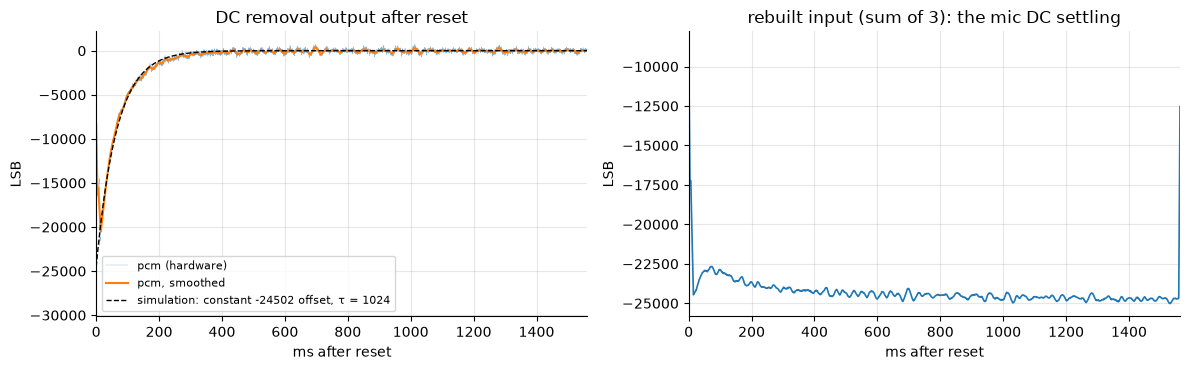

mic DC after settling: -24502 per sum = -8167 LSB per 18-bit sample (-6.2% of full scale)
pcm mean over the last 0.5 s: -16.4 LSB; largest |pcm| 28677 (clips at 32768)


In [10]:
raw = open('captures/reset.bin', 'rb').read()
s, c, st = decode(raw)
print('first sample counters:', c[:4], '(1 = the second sample after reset)')
p = np.array(s, dtype=np.int64)
acc, sums = int(p[0]), []
for v in p:
    sums.append(v + (acc >> 10)); acc += v
sums = np.array(sums)
t = np.arange(len(p)) / FS * 1e3
k = 128
smooth = lambda v: np.convolve(v, np.ones(k) / k, mode='same')
dc_in = np.mean(sums[int(0.2 * FS):])
step = dc_in * (1 - 2.0 ** -10) ** np.arange(len(p))     # ideal response to a constant offset, a = 2^-10

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(t, p, lw=0.3, alpha=0.5, label='pcm (hardware)')
ax[0].plot(t, smooth(p), lw=1.5, label='pcm, smoothed')
ax[0].plot(t, step, 'k--', lw=1, label=f'simulation: constant {dc_in:.0f} offset, τ = 1024')
ax[0].set(xlabel='ms after reset', ylabel='LSB', title='DC removal output after reset'); ax[0].legend(fontsize=8)
ax[1].plot(t, smooth(sums), lw=1.2)
ax[1].set(xlabel='ms after reset', ylabel='LSB', title='rebuilt input (sum of 3): the mic DC settling')
for a in ax: a.set_xlim(0, t[-1])
plt.tight_layout(); plt.show()
print(f'mic DC after settling: {dc_in:.0f} per sum = {dc_in/3:.0f} LSB per 18-bit sample ({dc_in/3/2**17*100:.1f}% of full scale)')
print(f'pcm mean over the last 0.5 s: {p[-int(0.5*FS):].mean():.1f} LSB; largest |pcm| {np.abs(p).max()} (clips at 32768)')

## Through the planned FFT output and MCU steps

The same steps as `avipe_chain.ipynb`, on one real frame from each capture:

1. **FFT output format.** A 512-point FFT, then real and imaginary parts stored in
   16 bits each, with one power-of-2 scale `2^e` for the whole frame (block floating point).
   SQNR measures what that storage loses.
2. **MCU.** Hamming window in the frequency domain, `0.54 X[k] − 0.23 (X[k−1] + X[k+1])`,
   then the magnitude of bins 1 to 254, the bars on the display, and the peak bin.

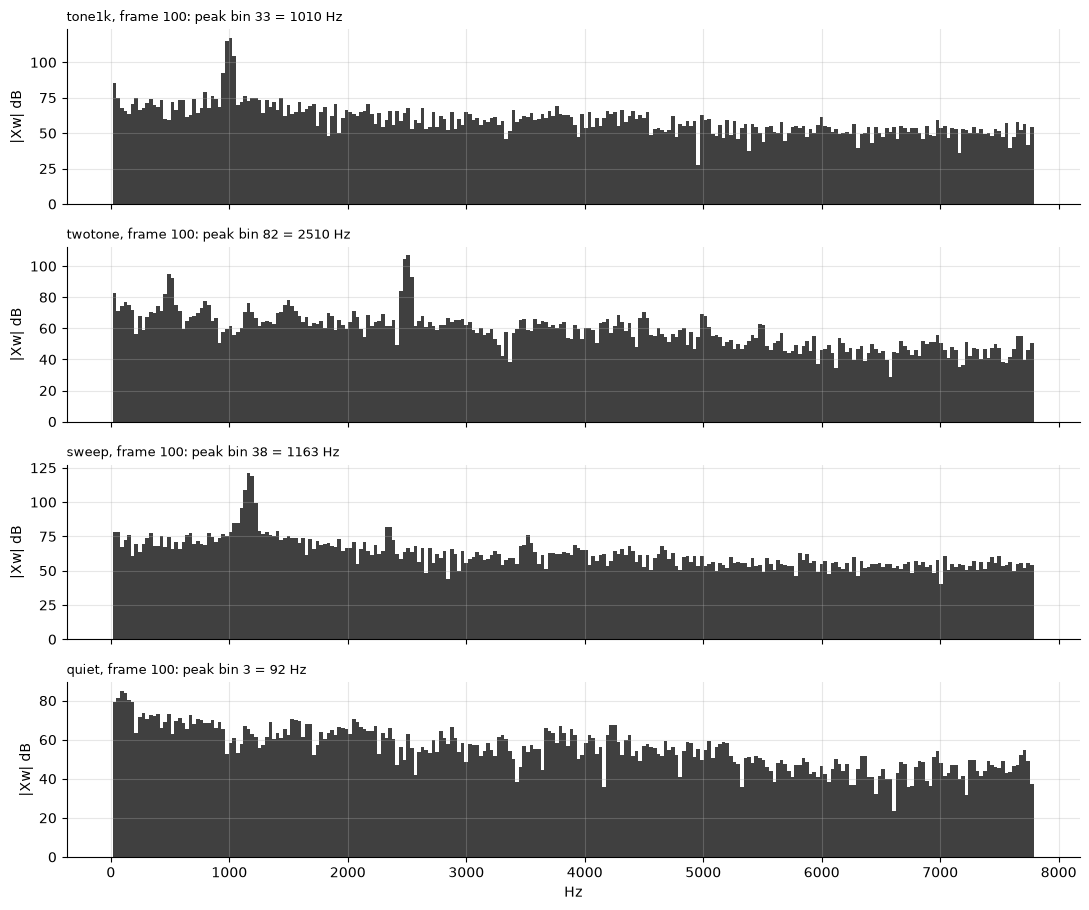

,capture,frame,scale e,SQNR (dB),peak bin,peak Hz
0,tone1k,100,6,71.1,33,1010
1,twotone,100,4,73.0,82,2510
2,sweep,100,6,75.2,38,1163
3,quiet,100,0,78.4,3,92


In [11]:
FFT_OUT_BITS = 16
def fft_path(frame):
    X = np.fft.fft(frame)
    top = 2 ** (FFT_OUT_BITS - 1) - 1
    big = max(np.abs(X.real).max(), np.abs(X.imag).max())
    e = max(0, int(np.ceil(np.log2(big / top))))
    q = lambda v: np.clip(np.rint(v / 2 ** e), -top - 1, top)
    Xq = (q(X.real) + 1j * q(X.imag)) * 2.0 ** e
    sqnr = 10 * np.log10(np.sum(np.abs(X) ** 2) / max(np.sum(np.abs(Xq - X) ** 2), 1e-30))
    kk = np.arange(1, 255)
    mag = np.abs(0.54 * Xq[kk] - 0.23 * (Xq[kk - 1] + Xq[kk + 1]))
    return kk, mag, e, sqnr

picks = [('tone1k', 100), ('twotone', 100), ('sweep', 100), ('quiet', 100)]
fig, ax = plt.subplots(len(picks), 1, figsize=(11, 2.3 * len(picks)), sharex=True)
rows = []
for a, (name, fi) in zip(ax, picks):
    fr = frames(caps[name])[fi]
    kk, mag, e, sqnr = fft_path(fr)
    db = 20 * np.log10(np.maximum(mag, 1))
    pk = kk[np.argmax(mag)]
    a.bar(kk * BIN_HZ, db, width=BIN_HZ, color='0.25')
    a.set_title(f'{name}, frame {fi}: peak bin {pk} = {pk*BIN_HZ:.0f} Hz', fontsize=9, loc='left')
    a.set_ylabel('|Xw| dB'); a.set_ylim(0, None)
    rows.append((name, fi, e, round(sqnr, 1), pk, round(pk * BIN_HZ)))
ax[-1].set_xlabel('Hz')
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows, columns=['capture', 'frame', 'scale e', 'SQNR (dB)', 'peak bin', 'peak Hz']))

SQNR is the error from storing the FFT in 16 + 16 bits with one shared scale, compared
with the exact FFT. Loud frames need a larger `e`, so quiet bins in them lose detail,
but the peaks and the bar heights the display draws are unaffected.

## Speaker tone test: played vs heard

The PC played one tone at a time from the VG27B monitor speaker (4 s, amplitude 0.3),
and `serial_capture.py` recorded 2 s of mic samples during each: `t437`, `t1234`,
`t2718`, `t4321`, `t6789`. The frequencies were chosen off the bin centers on purpose.
Each frame gets the 512-point Hamming FFT; the peak is the loudest bin from bin 3 up
(bins 0 to 2 hold the fan hum), and a parabola through the 3 bins around it refines it.
The dashed red line is the tone that was played.

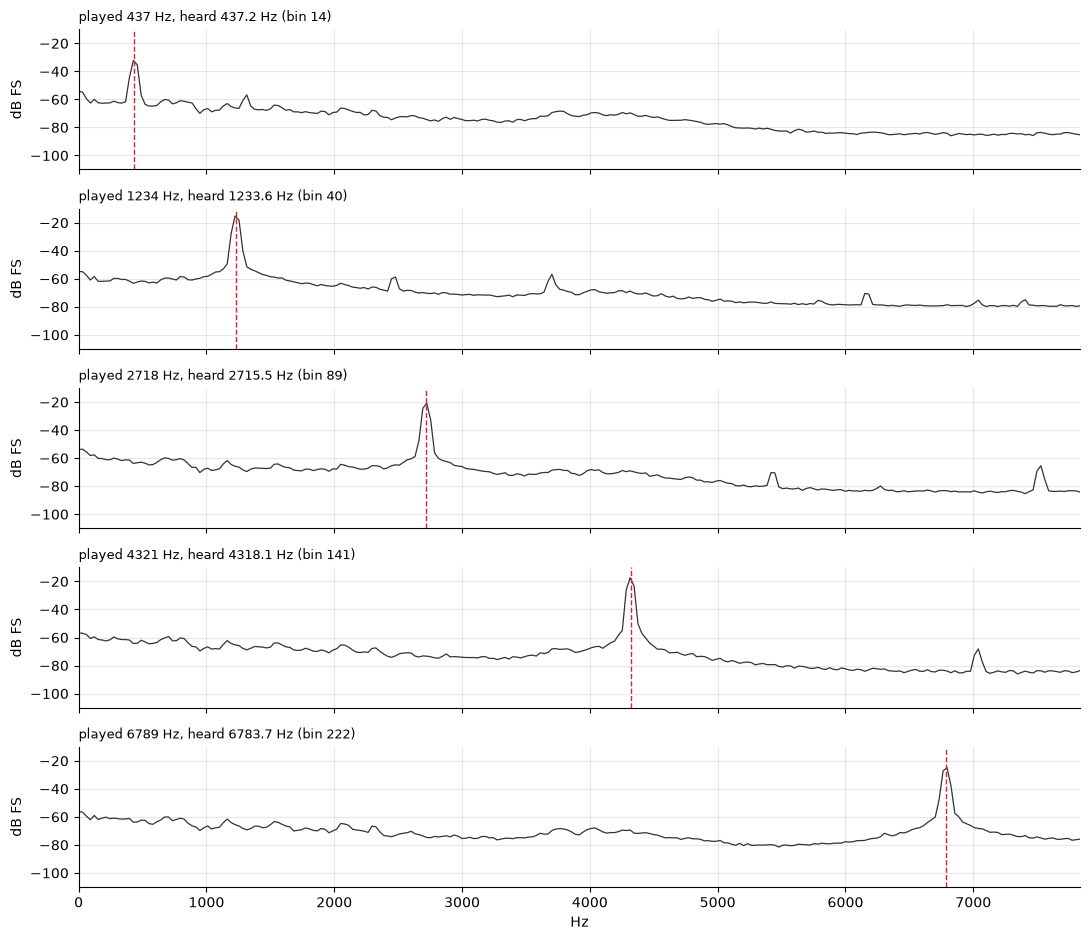

,played (Hz),peak bin,bin center (Hz),refined (Hz),error (Hz),frames with that peak,dB above median
0,437,14,428.5,437.2,0.2,103/103,42.1
1,1234,40,1224.2,1233.6,-0.4,103/103,55.9
2,2718,89,2723.8,2715.5,-2.5,102/103,49.6
3,4321,141,4315.3,4318.1,-2.9,103/103,55.9
4,6789,222,6794.3,6783.7,-5.3,102/103,46.9


PASS: every tone found in its bin


In [12]:
TONES = [437, 1234, 2718, 4321, 6789]
fig, ax = plt.subplots(len(TONES), 1, figsize=(11, 1.9 * len(TONES)), sharex=True)
rows = []
for a, hz in zip(ax, TONES):
    raw = open(f'captures/t{hz}.bin', 'rb').read()
    x = np.array(decode(raw)[0][SKIP:], dtype=float)
    S = spectra(x)                                   # dB FS, one row per frame
    pk = np.argmax(S[:, 3:], axis=1) + 3             # loudest bin in each frame
    avg = 10 * np.log10(np.mean(10 ** (S / 10), axis=0))
    k = int(np.bincount(pk).argmax())
    l, m, r = avg[k - 1:k + 2]
    fine = (k + 0.5 * (l - r) / (l - 2 * m + r)) * BIN_HZ
    a.plot(freqs, avg, lw=0.9, color='0.2')
    a.axvline(hz, color='tab:red', ls='--', lw=1)
    a.set_ylim(-110, -10)
    a.set_title(f'played {hz} Hz, heard {fine:.1f} Hz (bin {k})', fontsize=9, loc='left')
    a.set_ylabel('dB FS')
    rows.append((hz, k, round(k * BIN_HZ, 1), round(fine, 1), round(fine - hz, 1),
                 f'{(pk == k).sum()}/{len(pk)}', round(m - np.median(avg[3:]), 1)))
ax[-1].set(xlabel='Hz', xlim=(0, FS / 2))
plt.tight_layout(); plt.show()
table = pd.DataFrame(rows, columns=['played (Hz)', 'peak bin', 'bin center (Hz)', 'refined (Hz)',
                                    'error (Hz)', 'frames with that peak', 'dB above median'])
display(table)
print('PASS: every tone found in its bin' if (abs(table['error (Hz)']) < BIN_HZ / 2).all() else 'CHECK: a tone is off')